In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
warnings.filterwarnings('ignore')
sns.set(style="whitegrid")

## **Data Wrangling**

In [6]:
df = pd.read_csv('C:/Users/ASUS/.vscode/rain-medan/data/MDNPLNA_rain_daily.csv')

In [7]:
df.head()

,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,9/30/2025 0:00,28.0,17.0,32.0,0.0,NaN,NaN,10.5,NaN,1008.3,NaN
1,10/1/2025 0:00,26.3,22.0,31.0,6.0,NaN,NaN,9.8,NaN,1009.5,NaN
2,10/2/2025 0:00,27.9,25.0,32.0,2.8,NaN,NaN,7.3,NaN,1009.9,NaN
3,10/3/2025 0:00,26.4,24.0,29.0,9.5,NaN,NaN,7.7,NaN,1011.4,NaN
4,10/4/2025 0:00,26.3,23.0,30.0,5.0,NaN,NaN,10.6,NaN,1011.4,NaN


In [8]:
df.describe()

,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
count,366.000000,366.000000,366.000000,366.000000,0.0,0.0,366.000000,0.0,366.000000,0.0
mean,27.521858,24.552732,30.929508,5.133060,NaN,NaN,7.490984,NaN,1009.447268,NaN
std,0.959288,0.997878,1.526910,8.727138,NaN,NaN,3.023316,NaN,1.362886,NaN
min,23.700000,17.000000,25.000000,0.000000,NaN,NaN,2.600000,NaN,1005.600000,NaN
25%,26.900000,24.000000,30.000000,0.000000,NaN,NaN,5.000000,NaN,1008.400000,NaN
50%,27.700000,25.000000,31.000000,1.700000,NaN,NaN,6.550000,NaN,1009.500000,NaN
75%,28.275000,25.000000,32.000000,7.175000,NaN,NaN,9.775000,NaN,1010.400000,NaN
max,29.500000,27.000000,35.000000,82.500000,NaN,NaN,20.700000,NaN,1013.000000,NaN


In [10]:
df.shape

(366, 11)

In [11]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

df.columns

Index(['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt',
       'pres', 'tsun'],
      dtype='str')

In [13]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date")

In [14]:
df[df["date"].isna()]

,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun


In [15]:
rain_col = "prcp"

print("--- Deskripsi Curah Hujan (prcp) ---")
print(df[rain_col].describe())

print("\n--- Jumlah Missing Values pada prcp ---")
print(df[rain_col].isna().sum())

--- Deskripsi Curah Hujan (prcp) ---
count    366.000000
mean       5.133060
std        8.727138
min        0.000000
25%        0.000000
50%        1.700000
75%        7.175000
max       82.500000
Name: prcp, dtype: float64

--- Jumlah Missing Values pada prcp ---
0


## **EDA**

In [31]:
df["date"] = pd.to_datetime(df["date"])
df["prcp"] = df["prcp"].fillna(0.0)

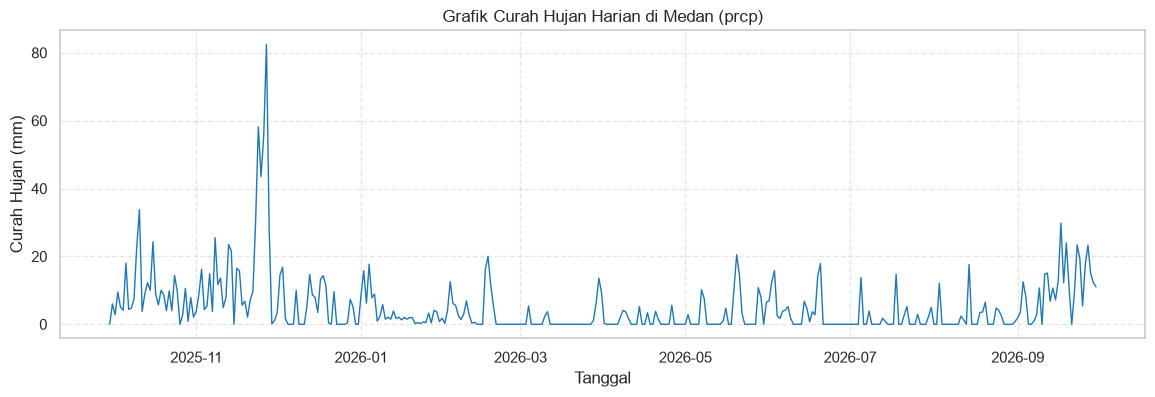

In [32]:
plt.figure(figsize=(14, 4))
plt.plot(df["date"], df["prcp"], color="tab:blue", linewidth=1)
plt.title("Grafik Curah Hujan Harian di Medan (prcp)")
plt.xlabel("Tanggal")
plt.ylabel("Curah Hujan (mm)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

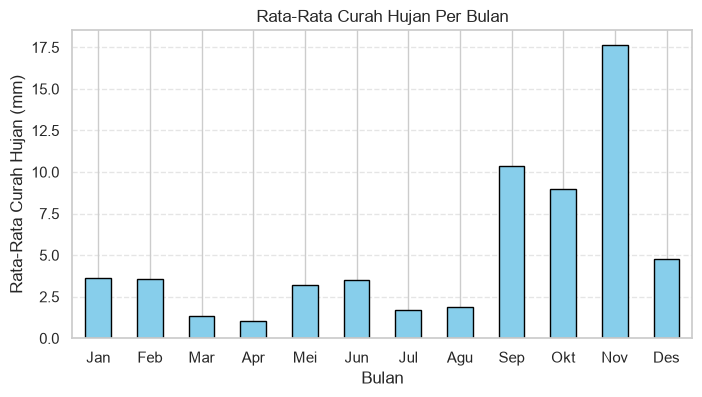

In [33]:
df["month"] = df["date"].dt.month
monthly_prcp = df.groupby("month")["prcp"].mean()

plt.figure(figsize=(8, 4))
monthly_prcp.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Rata-Rata Curah Hujan Per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Rata-Rata Curah Hujan (mm)")
plt.xticks(
    ticks=range(0, 12),
    labels=[
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "Mei",
        "Jun",
        "Jul",
        "Agu",
        "Sep",
        "Okt",
        "Nov",
        "Des",
    ],
    rotation=0,
)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

Bulan paling hujan adalah bulan **November (11)** dan
Bulan paling kering adalah bulan **April (4)**

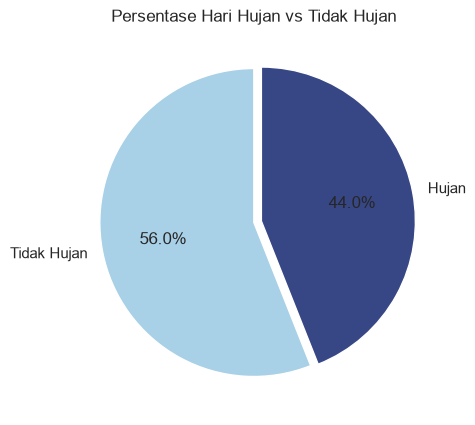

In [34]:
is_rainy = df["prcp"] > 0.5
rain_counts = is_rainy.value_counts(normalize=True) * 100

plt.figure(figsize=(5, 5))
plt.pie(
    rain_counts,
    labels=["Tidak Hujan", "Hujan"],
    autopct="%.1f%%",
    colors=["#a8d0e6", "#374785"],
    startangle=90,
    explode=(0, 0.05),
)
plt.title("Persentase Hari Hujan vs Tidak Hujan")
plt.show()

Presentase hari yang hujan lebih kecil daripada hari yang tidak hujan, artinya 56% hari hari di Medan Tidak hujan dalam jangka waktu setahun

## **Feature Engineering**

In [57]:
cols_empty = [
    col
    for col in df.columns
    if df[col].isna().all() or col in ["snow", "wpgt", "tsun"]
]
df_clean = df.drop(columns=cols_empty, errors="ignore").copy()

if "prcp" in df_clean.columns:
  df_clean["prcp"] = df_clean["prcp"].fillna(0.0)

In [58]:
# Target hujan besok

df["target_prcp_tomorrow"] = df["prcp"].shift(-1)
df["target_rain_tomorrow"] = (
    df["target_prcp_tomorrow"] > 0.5
).astype(int)  # 1 jika hujan, 0 jika tidak

In [59]:
# Fitur masa lalu

for col in ["prcp", "tavg", "tmin", "tmax", "wspd", "pres", "wdir"]:
  if col in df_clean.columns:
    df_clean[f"{col}_lag1"] = df_clean[col].shift(1)
    df_clean[f"{col}_lag2"] = df_clean[col].shift(2)
    df_clean[f"{col}_lag3"] = df_clean[col].shift(3)

In [60]:
# Rata rata dalam 3 sampai 7 hari terakhir

if "prcp" in df_clean.columns:
  df_clean["prcp_roll_mean_3d"] = (
      df_clean["prcp"].shift(1).rolling(window=3).mean()
  )
  df_clean["prcp_roll_mean_7d"] = (
      df_clean["prcp"].shift(1).rolling(window=7).mean()
  )

In [40]:
df["day_of_year"] = df["date"].dt.dayofyear

In [61]:
df_model = df_clean.dropna().reset_index(drop=True)

print("Ukuran df_model setelah Feature Engineering:", df_model.shape)

Ukuran df_model setelah Feature Engineering: (358, 31)


## **Model**

In [62]:
# Split data

features = [col for col in df_model.columns if "_lag" in col or "_roll" in col]
target = "target_rain_tomorrow"

split_idx = int(len(df_model) * 0.8)

X_train = df_model.iloc[:split_idx][features]
y_train = df_model.iloc[:split_idx][target]

X_test = df_model.iloc[split_idx:][features]
y_test = df_model.iloc[split_idx:][target]

print(f"Jumlah Data Latih (Train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (Test)  : {X_test.shape[0]} baris")

Jumlah Data Latih (Train): 286 baris
Jumlah Data Uji (Test)  : 72 baris


In [63]:
print("df_model:", df_model.shape)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

df_model: (358, 31)
X_train: (286, 20)
X_test : (72, 20)
y_train: (286,)
y_test : (72,)


In [64]:
# Tebak kondisi besok = kondisi hari ini (prcp_lag1)

from sklearn.metrics import accuracy_score

y_pred_baseline = (X_test["prcp_lag1"] > 0.5).astype(int)

print("=== EVALUASI BASELINE (Tebak Hari Ini = Besok) ===")
print(
    "Accuracy Baseline:", round(accuracy_score(y_test, y_pred_baseline), 4)
)

=== EVALUASI BASELINE (Tebak Hari Ini = Besok) ===
Accuracy Baseline: 0.5278


In [65]:
# Model pertama

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [66]:
# Evaluasi model

y_pred = model.predict(X_test)

print("\n=== EVALUASI MODEL RANDOM FOREST ===")
print("Accuracy Model:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


=== EVALUASI MODEL RANDOM FOREST ===
Accuracy Model: 0.5

Classification Report:
               precision    recall  f1-score   support

           0       0.44      0.70      0.54        30
           1       0.62      0.36      0.45        42

    accuracy                           0.50        72
   macro avg       0.53      0.53      0.50        72
weighted avg       0.55      0.50      0.49        72



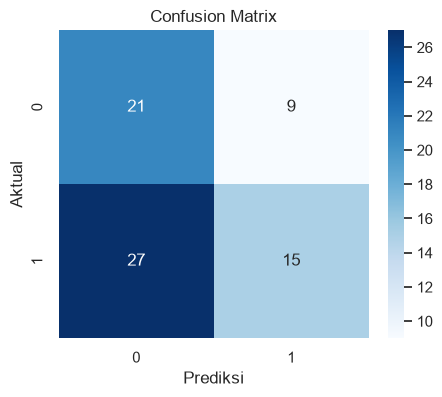

In [67]:
# Matrix visual

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix")
plt.show()

In [71]:
joblib.dump(model, "C:/Users/ASUS/.vscode/rain-medan/models/rain_prediction_rf.pkl")
print("\nModel berhasil disimpan di 'C:/Users/ASUS/.vscode/rain-medan/models/rain_prediction_rf.pkl'")


Model berhasil disimpan di 'C:/Users/ASUS/.vscode/rain-medan/models/rain_prediction_rf.pkl'


In [73]:
import os

df_model.to_csv("C:/Users/ASUS/.vscode/rain-medan/data/medan_weather_cleaned.csv", index=False)

print("Data berhasil disimpan ke 'data/medan_weather_cleaned.csv'!")

Data berhasil disimpan ke 'data/medan_weather_cleaned.csv'!
